In [140]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import rcParams
import time
from copy import copy as dup
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit
from pint import UnitRegistry; AssignQuantity = UnitRegistry().Quantity
from importlib import reload
from matplotlib.gridspec import GridSpec

# My modules
import sys; sys.path.append('..')
import importlib  # Import the importlib module
import QLCstuff as QLC
import f90nml

In [141]:
# Graphics parameters
%matplotlib inline
ticklabelsize = 11
fontsize = 15
linewidth = 2

### Attempting hollowing


Using parameter file Panel (d).nml ...
sigmaI_corner = 22 percent
sigma0 = 20 percent
c_r = 9.8 percent
Nbar 1
Nstar 0.1
h_layer = 0.37 nanometer
D = 0.0002 micrometer ** 2 / microsecond
nu_kin = 0.264 / microsecond
L = 50 micrometer
nx (crystal) = 11001
t_eq = 1.5 microsecond
Spacing of points on the ice surface = 0.009090909090907928 micrometer
omega_kin = 0.396 dimensionless

Using parameter file Panel (d).nml ...
runtime = 1.1 millisecond
odemethod = RK45
This is a run from time 0.0 millisecond to 1.1 millisecond
dt = 22.448979591836736 microsecond
0.22 dimensionless 0.22 0.2
10 % elapsed time is 0.170 minutes
20 % elapsed time is 0.309 minutes
30 % elapsed time is 0.450 minutes
40 % elapsed time is 0.595 minutes
50 % elapsed time is 0.740 minutes
60 % elapsed time is 0.889 minutes
70 % elapsed time is 1.027 minutes
80 % elapsed time is 1.171 minutes
90 % elapsed time is 1.317 minutes
100% done
status =  0
message =  The solver successfully reached the end of the integration inter

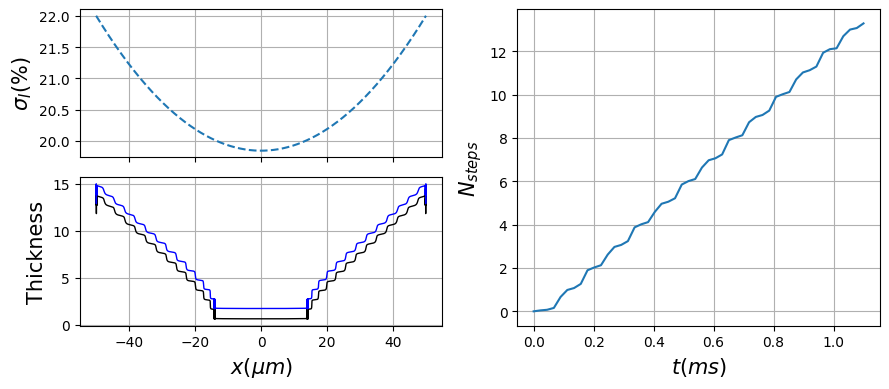

In [142]:
# Parameters
GIfile =     "Panel (d).nml"
figurefile = "Panel (d).png"

sigmaI_corner, sigma0, c_r, sigmaI_QLC, Nbar, Nstar, h_layer, D, nu_kin, L, nx_crystal, t_eq, x_QLC, DoverL2pi2, Doverdeltax2 = \
    QLC.get_system_parameters(GIfile, AssignQuantity)
odemethod, tkeep_1Darr, Ntot_init_1D, NQLL_init_1D = \
    QLC.get_runtime_parameters(GIfile, nx_crystal, Nstar, Nbar, AssignQuantity)

# Run the simulation in Cartesian space
Ntotkeep_1D, NQLLkeep_1D = QLC.run_f1d(\
           NQLL_init_1D,Ntot_init_1D,tkeep_1Darr,\
           Nbar, Nstar, sigma0, nu_kin, Doverdeltax2, t_eq, sigmaI_QLC,\
           AssignQuantity,\
           verbose=0, odemethod=odemethod)
Nicekeep_1D = Ntotkeep_1D-NQLLkeep_1D

# Graphical output
fig = QLC.report_1d_growth_results_with_sigma(\
        x_QLC,tkeep_1Darr.to('millisecond'),NQLLkeep_1D,Ntotkeep_1D,Nicekeep_1D,sigmaI_QLC.to('percent'))
fig.savefig(figurefile, dpi=200)

### Analysis of spacing

Npts 11001
dx 0.009090909090907928 micrometer
dpts_dx 220.02 / micrometer
index_of_max 7271
dpts_dLayer_min 268.55379862216245


/Users/nesh/anaconda3/lib/python3.10/site-packages/matplotlib/cbook.py:1355: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asarray(x, float)
/Users/nesh/anaconda3/lib/python3.10/site-packages/pint/facets/plain/quantity.py:1006: RuntimeWarning: divide by zero encountered in divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)


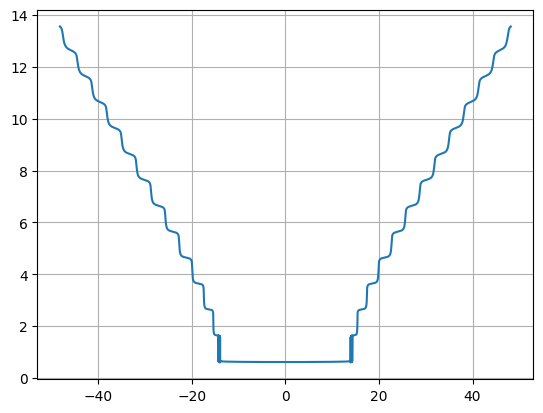

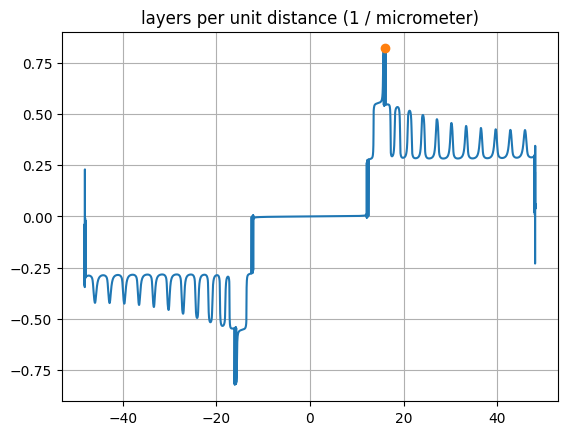

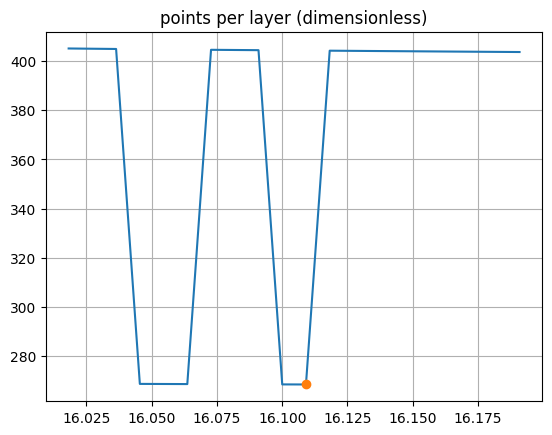

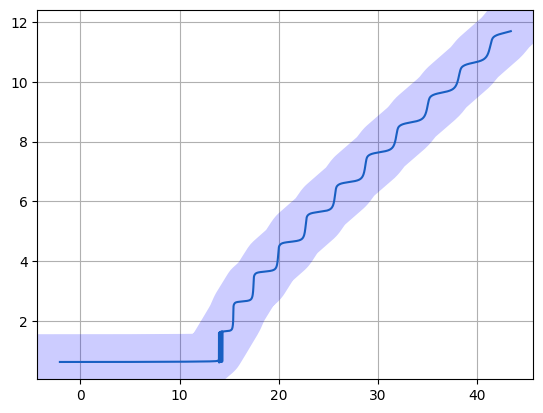

In [143]:
# Basic configuration parameters
Npts = np.size(x_QLC); print('Npts',Npts)
dx = x_QLC[1]-x_QLC[0]; print('dx',dx)
dpts_dx = Npts/L; print('dpts_dx',dpts_dx)
x_short = x_QLC[1:]

# Getting a smoothed version of the ice thickness
def smooth(y, box_pts):
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    return y_smooth
nsmooth = 400
iskip = 200
Nicekeep_smooth = smooth(Nicekeep_1D[-1,:],nsmooth)
plt.figure()
plt.plot(x_short[iskip:-iskip],Nicekeep_1D[-1,iskip:-iskip-1])
# plt.plot(x_short[iskip:-iskip],Nicekeep_smooth[iskip:-iskip-1],alpha=0.5,linewidth=4,color='blue')
plt.grid(True)

# Calculating the number of layers per unit horizontal distance
dLayers_dx = np.diff(Nicekeep_smooth)/dx
index_of_max = np.argmax(dLayers_dx[iskip:-iskip])+iskip; print('index_of_max',index_of_max)
plt.figure()
plt.plot(x_short.magnitude[iskip:-iskip],dLayers_dx.magnitude[iskip:-iskip])
plt.plot(x_short.magnitude[index_of_max],dLayers_dx.magnitude[index_of_max],'o')
plt.grid(True)
plt.title('layers per unit distance ' + '('+str(dLayers_dx.units)+')')

# Calculating the number of points per layer
dpts_dLayer = dpts_dx/dLayers_dx
ilook = 10; i1 = index_of_max-ilook; i2 = index_of_max+ilook
dpts_dLayer_min = np.min(dpts_dLayer.magnitude[i1:i2]); print('dpts_dLayer_min',dpts_dLayer_min)
plt.figure()
plt.plot(x_short.magnitude[i1:i2],dpts_dLayer.magnitude[i1:i2])
plt.plot(x_short.magnitude[index_of_max],dpts_dLayer.magnitude[index_of_max],'o')
plt.grid(True)
plt.title('points per layer ' + '('+str(dpts_dLayer.units)+')')

# Expanded version of the 1st plot
ilook = 2000; i1 = index_of_max-ilook; i2 = index_of_max+ilook+1000
plt.figure()
plt.plot(x_short[i1:i2],Nicekeep_1D[-1,i1:i2])
# plt.plot(x_short.magnitude[index_of_max],Nicekeep_1D[-1,index_of_max],'o')
plt.plot(x_short[i1:i2],Nicekeep_smooth[i1:i2],color='blue',linewidth=40,alpha=.2)
plt.grid(True)